In [7]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
import os
import sys

import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.util import add_cyclic_point

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cmocean

import src.plotting as plot
import src.utils as utils
from src.config import *

In [9]:
AMOC_ON = "pi/pi-amoc-on"
AMOC_OFF = "pi/pi-amoc-off"

In [ ]:
# Original data paths
fpaths = {
    "sic_amoc_on": os.path.join(DIR_OUTPUT, AMOC_ON, "sic.nc"),
    "sic_amoc_off": os.path.join(DIR_OUTPUT, AMOC_OFF, "sic.nc"),
    "gis_amoc_on": os.path.join(DIR_OUTPUT, AMOC_ON, "ice_GRL-16KM.nc"),
    "gis_amoc_off": os.path.join(DIR_OUTPUT, AMOC_OFF, "ice_GRL-16KM.nc"),
}
source_files_available = all(os.path.isfile(path) for path in fpaths.values())

DIR_SEA_ICE_CACHE = os.path.join(DIR_DATA, "sea_ice")
os.makedirs(DIR_SEA_ICE_CACHE, exist_ok=True)

print(source_files_available)

False


Using original files: False
Processed data: /nethome/terps020/analysis/ms_AMOC-GrIS/data/sea_ice/sea_ice_processed_years_0_1000.nc
vmin = 0.0, vmax = 3.3037664890289307
vmin = 0.0, vmax = 3.3037664890289307
vmin = 0.0, vmax = 3.0903217792510986
vmin = 0.0, vmax = 3.0903217792510986


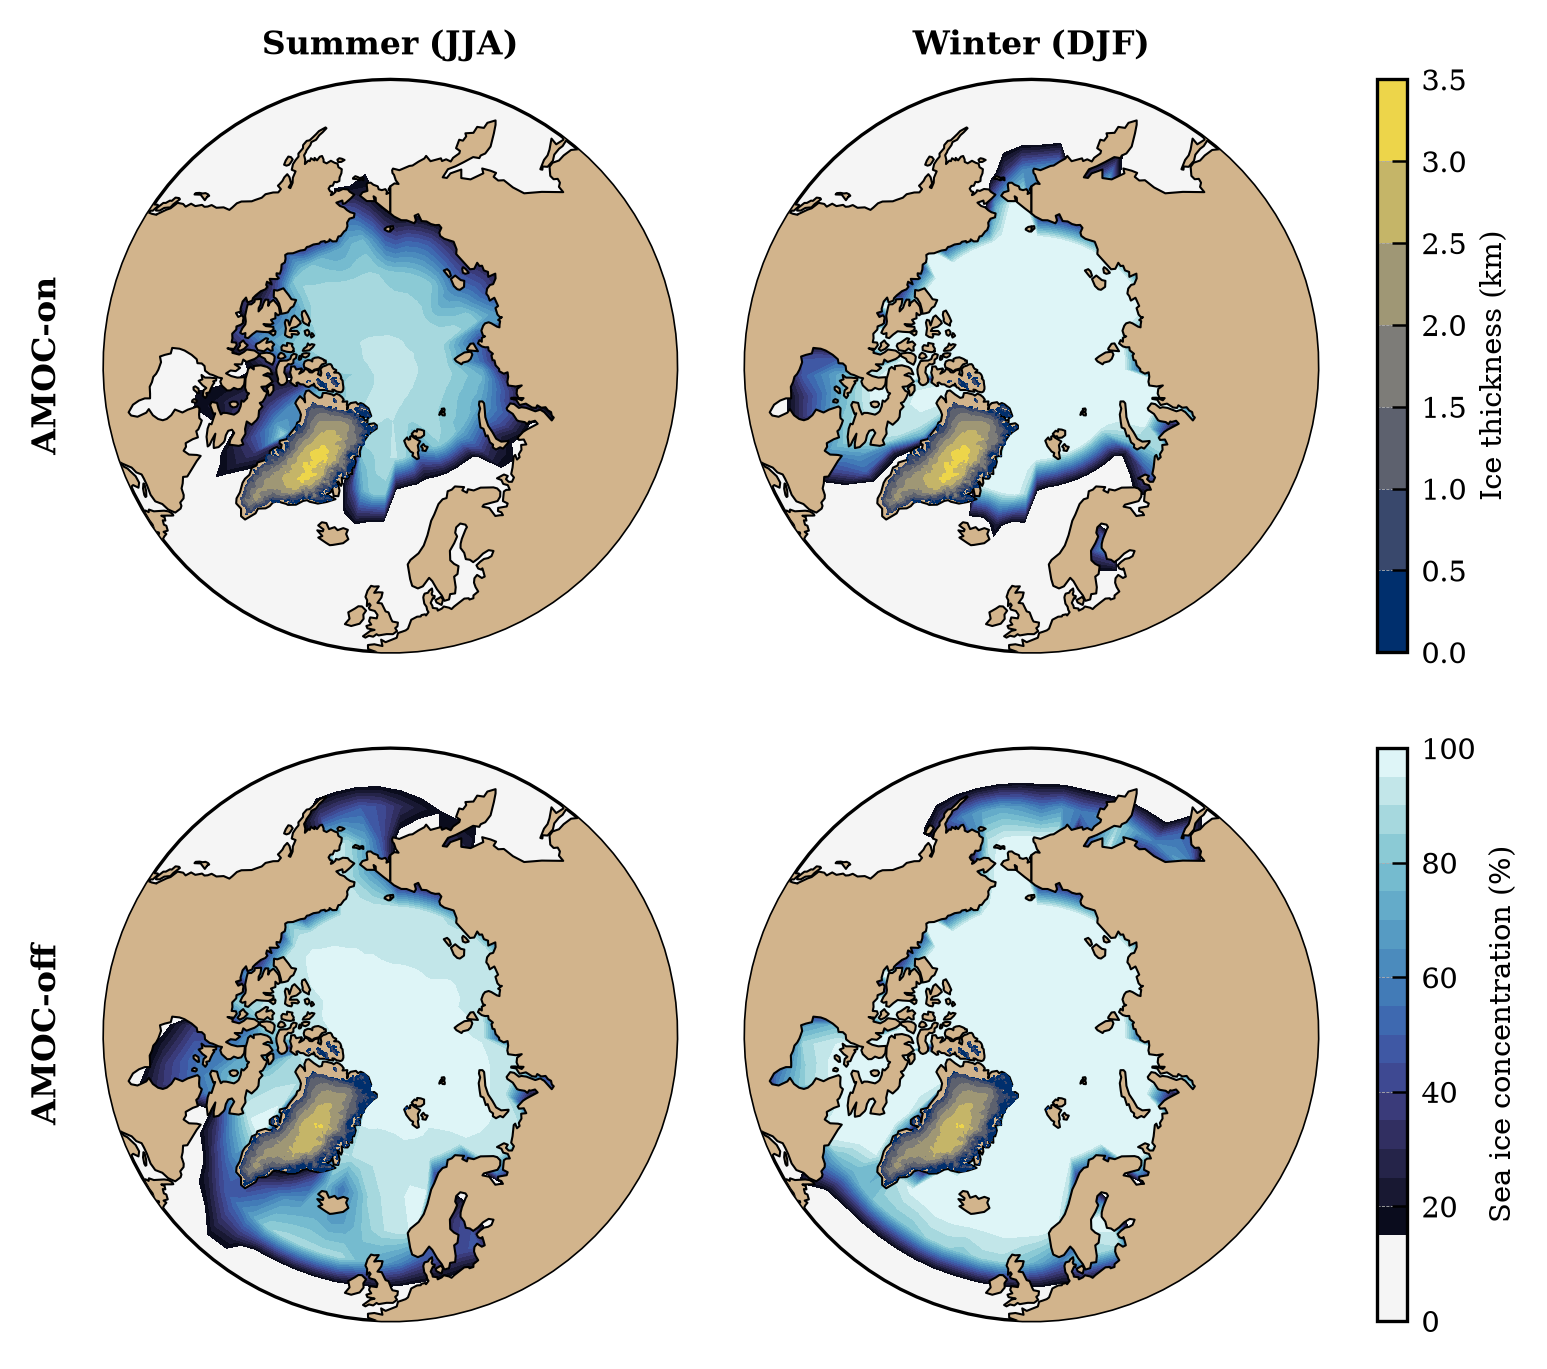

In [11]:
fig = plt.figure(figsize=(0.7*plot.width_twocol, plot.height_twocol), constrained_layout=True)

projection = ccrs.Orthographic(central_longitude=0, central_latitude=90)
lat_slice = slice(45, None)
year_slice = slice(0, 1000)  # Example: first 10 years

fpath_processed = os.path.join(
    DIR_SEA_ICE_CACHE,
    f"sea_ice_processed_years_{year_slice.start}_{year_slice.stop}.nc",
)
season_months = {
    "summer": [5, 6, 7],
    "winter": [11, 0, 1],
}

if source_files_available:
    processed_arrays = {}
    for scenario in ("amoc_on", "amoc_off"):
        with xr.open_dataset(fpaths[f"sic_{scenario}"], mode="r") as ds_sic, xr.open_dataset(
            fpaths[f"gis_{scenario}"], mode="r"
        ) as ds_gis:
            for season, month_inds in season_months.items():
                ds_plot = ds_sic["fsic"].sel(lat=lat_slice)
                ds_plot = ds_plot.isel(month=month_inds).mean(dim="month")
                processed_arrays[f"sic_{scenario}_{season}"] = (
                    ds_plot.isel(time=year_slice).mean(dim="time").load()
                )

            processed_arrays[f"gis_{scenario}"] = (
                ds_gis["H_ice"].isel(time=year_slice).mean(dim="time").load()
            )

    # Isolate dimensions per variable so different native grids cannot be aligned.
    ds_processed = xr.Dataset(
        {
            name: array.reset_coords(drop=True).rename(
                {dim: f"{name}_{dim}" for dim in array.dims}
            )
            for name, array in processed_arrays.items()
        }
    )
    ds_processed.to_netcdf(fpath_processed)
else:
    if not os.path.isfile(fpath_processed):
        raise FileNotFoundError(
            "Original sea-ice/GIS files and their processed cache are unavailable. "
            f"Expected sources: {list(fpaths.values())}; expected cache: {fpath_processed}"
        )

    ds_processed = xr.load_dataset(fpath_processed)
    processed_arrays = {
        name: ds_processed[name].rename(
            {dim: dim[len(name) + 1:] for dim in ds_processed[name].dims}
        )
        for name in ds_processed.data_vars
    }

print(f"Using original files: {source_files_available}")
print(f"Processed data: {fpath_processed}")

gs = fig.add_gridspec(
    2, 3,
    width_ratios=[1, 1, 0.05],
    wspace=0.1,
    hspace=0.1,
)

ax1 = fig.add_subplot(gs[0, 0], projection=projection)
ax2 = fig.add_subplot(gs[0, 1], projection=projection)
ax3 = fig.add_subplot(gs[1, 0], projection=projection)
ax4 = fig.add_subplot(gs[1, 1], projection=projection)

# Apply circular boundary to all main axes
plot.set_circular_boundary(ax1)
plot.set_circular_boundary(ax2)
plot.set_circular_boundary(ax3)
plot.set_circular_boundary(ax4)

# The third column holds the two colorbar axes.
cax1 = fig.add_subplot(gs[0, 2])
cax2 = fig.add_subplot(gs[1, 2])

panel_specs = [
    ("sic_amoc_on_summer", "gis_amoc_on", ax1),
    ("sic_amoc_on_winter", "gis_amoc_on", ax2),
    ("sic_amoc_off_summer", "gis_amoc_off", ax3),
    ("sic_amoc_off_winter", "gis_amoc_off", ax4),
]

for sic_key, gis_key, ax in panel_specs:
    ds_plot = processed_arrays[sic_key]

    # Add cyclic point to longitude for better plotting
    # (otherwise there is a gap between 180 and -180)
    ds_plot_cyclic, lon_cyclic = add_cyclic_point(ds_plot, coord=ds_plot.lon)

    # Close gap at the North Pole
    lat = ds_plot["lat"].values
    lat_pole = np.append(lat, 90)
    pole_row = np.mean(ds_plot_cyclic[lat == lat.max(), :], axis=0)  # Mean of last row
    ds_plot_cyclic = np.vstack([ds_plot_cyclic, pole_row])

    sic = ds_plot_cyclic * 100  # Convert to percentage

    cmap = cmocean.cm.ice
    cmap.set_under("whitesmoke")

    # mcolors.Normalize values from 0 to 100 instead of 0 to 1
    norm = mcolors.Normalize(vmin=15, vmax=100)

    # Make masked areas black
    cf_ice = ax.contourf(
        lon_cyclic, lat_pole, sic, cmap=cmap, transform=ccrs.PlateCarree(), norm=norm,
        levels=np.linspace(0, 100, 21, endpoint=True) #, vmin=15, vmax=100
    )

    # Plot land and coastlines on top
    ax.add_feature(
        cfeature.LAND.with_scale("110m"), zorder=10, edgecolor="black", facecolor="tan",
        linewidth=0.5
    )

    ### Plot Greenland Ice Sheet on top for Arctic sector
    ds_GIS_plot = processed_arrays[gis_key]

    # Transform the dataset coordinates in km to degrees
    # This includes changing xc and yc to degrees
    ds_GIS_plot = utils.transform_GIS_to_degrees(ds_GIS_plot)
    lon = ds_GIS_plot.lon.values
    lat = ds_GIS_plot.lat.values

    # Change units from m to km
    ds_GIS_plot = ds_GIS_plot / 1000.0

    # Maximum and minimum values for plotting
    print(f"vmin = {ds_GIS_plot.min().values}, vmax = {ds_GIS_plot.max().values}")
    vmin = 0.001
    vmax = 3.5
    levels = np.linspace(vmin, vmax, 8)

    # Mask values below vmin
    ds_GIS_plot = ds_GIS_plot.where(ds_GIS_plot >= vmin)

    # Plot with norm from vmin to vmax
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)

    # cmap = cmocean.cm.ice
    cmap = plt.cm.cividis
    # cmap.set_under("white")

    cf_GIS = ax.contourf(
        lon, lat, ds_GIS_plot, cmap=cmap,
        transform=ccrs.PlateCarree(), norm=norm, levels=levels,
        zorder=20
    )

cbar_GIS = plt.colorbar(cf_GIS, cax=cax1)
cbar_GIS.set_label("Ice thickness (km)")
cbar_GIS.set_ticks([vmin, 0.5, 1, 1.5, 2, 2.5, 3, 3.5])
cbar_GIS.set_ticklabels(["0.0", "0.5", "1.0", "1.5", "2.0", "2.5", "3.0", "3.5"])
cbar_GIS.ax.tick_params(labelsize=7)

cbar_ice = plt.colorbar(cf_ice, cax=cax2)
cbar_ice.set_label("Sea ice concentration (%)")
cbar_ice.set_ticks([0, 20, 40, 60, 80, 100])
cbar_ice.ax.tick_params(labelsize=7)

ax1.set_title("Summer (JJA)", fontweight="bold", fontsize=8)
ax2.set_title("Winter (DJF)", fontweight="bold", fontsize=8)

# Add vertically oriented text to the left of the ax1 and ax3 plots
ax1.text(-0.1, 0.5, "AMOC-on", va="center", ha="center", fontweight="bold", rotation="vertical", transform=ax1.transAxes)
ax3.text(-0.1, 0.5, "AMOC-off", va="center", ha="center", fontweight="bold", rotation="vertical", transform=ax3.transAxes)

plt.savefig(os.path.join(DIR_FIG, "sea_ice_comparison_spatial.pdf"), format="pdf")